# ⚔️ Comparativo de Candidatos

Análise aprofundada dos principais candidatos, cenários de segundo turno e estatísticas.

**Inclui:**
- Perfil dos candidatos
- Comparativo direto
- Simulação de segundo turno
- Distância para maioria absoluta
- Análise de partidos e coligações

In [1]:

import json
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Setup plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

# Find repo root and data dir robustly
def find_data_dir():
    candidates = [
        Path("../data"),
        Path("data"),
        Path("./data"),
        Path(__file__).parent / "../data" if '__file__' in globals() else None,
    ]
    # Also try from cwd
    cwd = Path.cwd()
    for p in [cwd / "data", cwd.parent / "data", cwd / "../data", Path("/home/user/eleicoes-data/data")]:
        candidates.append(p)
    for c in candidates:
        if c and c.exists() and list(c.glob("*.json")):
            return c
    # fallback: search recursively up to 3 levels
    for base in [Path.cwd(), Path.cwd().parent, Path("/home/user/eleicoes-data")]:
        for sub in [base, base / "eleicoes-data"]:
            d = sub / "data"
            if d.exists():
                return d
    return Path("../data")

DATA_DIR = find_data_dir()
print(f"📁 Data directory: {DATA_DIR.resolve()}")

files = sorted(DATA_DIR.glob("*.json"))
print(f"📊 Found {len(files)} snapshot files")
if files:
    print(f"   First: {files[0].name}")
    print(f"   Last:  {files[-1].name}")


def load_snapshot(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def extract_candidates(snapshot):
    """Flatten TSE payload into list of dicts."""
    rows = []
    payload = snapshot['data']
    for cargo in payload.get('carg', []):
        for agr in cargo.get('agr', []):
            for par in agr.get('par', []):
                for cand in par.get('cand', []):
                    rows.append({
                        'seq': cand.get('seq'),
                        'numero': cand.get('n'),
                        'nome_completo': cand.get('nm'),
                        'nome_urna': cand.get('nmu'),
                        'partido': par.get('sg'),
                        'partido_nome': par.get('nm'),
                        'agregacao': agr.get('nm'),
                        'votos': int(cand.get('vap', 0) or 0),
                        'percentual': float(str(cand.get('pvap', '0')).replace(',', '.') or 0),
                        'percentual_n': float(str(cand.get('pvapn', '0')).replace(',', '.') or 0),
                        'situacao': cand.get('st', ''),
                        'eleito': cand.get('e', ''),
                    })
    rows.sort(key=lambda x: x['votos'], reverse=True)
    return rows

def load_all_snapshots():
    all_data = []
    for fp in sorted(DATA_DIR.glob("*.json")):
        doc = load_snapshot(fp)
        meta = doc['metadata']
        data = doc['data']
        cands = extract_candidates(doc)
        # sections
        s = data.get('s', {})
        v = data.get('v', {})
        e = data.get('e', {})
        all_data.append({
            'file': fp.name,
            'path': fp,
            'scraped_at_utc': meta.get('scraped_at_utc'),
            'scraped_at_brasilia': meta.get('scraped_at_brasilia'),
            'tse_generated': meta.get('tse_file_generated_at'),
            'secoes_total': int(s.get('ts', 0) or 0),
            'secoes_apuradas': int(s.get('st', 0) or 0),
            'pct_apuradas': float(str(s.get('pst', '0')).replace(',', '.') or 0),
            'eleitorado': int(e.get('te', 0) or 0),
            'comparecimento': int(e.get('c', 0) or 0),
            'abstencao': int(e.get('a', 0) or 0),
            'votos_validos': int(v.get('vv', 0) or 0),
            'votos_brancos': int(v.get('vb', 0) or 0),
            'votos_nulos': int(v.get('vn', 0) or 0),
            'candidatos': cands,
            'metadata': meta,
            'raw': doc
        })
    return all_data

# Load once for convenience
all_snapshots = load_all_snapshots()
latest = all_snapshots[-1] if all_snapshots else None
if latest:
    print(f"✅ Latest snapshot: {latest['file']} | {latest['scraped_at_utc']}")
    print(f"   Seções: {latest['secoes_apuradas']}/{latest['secoes_total']} ({latest['pct_apuradas']}%)")


📁 Data directory: /home/user/eleicoes-data/data
📊 Found 43 snapshot files
   First: presidente_br_20261005_000211Z.json
   Last:  presidente_br_20261014_192215Z.json
✅ Latest snapshot: presidente_br_20261014_192215Z.json | 2026-10-14T19:22:15Z
   Seções: 499248/499248 (100.0%)


## 1. Ranking Completo com Detalhes

In [2]:

df = pd.DataFrame(latest['candidatos'])
df['pct_eleitorado'] = df['votos'] / latest['eleitorado'] * 100
df['pct_comparecimento'] = df['votos'] / latest['comparecimento'] * 100
df_display = df[['nome_urna','partido','agregacao','votos','percentual','pct_eleitorado','pct_comparecimento','situacao','eleito']]
df_display.style.format({
    'votos': '{:,}',
    'percentual': '{:.2f}%',
    'pct_eleitorado': '{:.2f}%',
    'pct_comparecimento': '{:.2f}%'
}).background_gradient(subset=['votos'], cmap='Blues')


,nome_urna,partido,agregacao,votos,percentual,pct_eleitorado,pct_comparecimento,situacao,eleito
0,FLAVIO BOLSONARO,PL,PARTIDO LIBERAL,"56,104,503",47.03%,35.34%,44.78%,2º turno,s
1,LULA,PT,BRASIL PRONTO PRA MAIS,"53,879,538",45.16%,33.94%,43.01%,2º turno,s
2,ESCRITOR AUGUSTO CURY,AVANTE,BRASIL DOS NOSSOS SONHOS,"3,448,569",2.89%,2.17%,2.75%,Não eleito,n
3,RENAN SANTOS,MISSÃO,PARTIDO MISSÃO,"2,675,887",2.24%,1.69%,2.14%,Não eleito,n
4,RONALDO CAIADO,PSD,PARTIDO SOCIAL DEMOCRÁTICO,"2,605,148",2.18%,1.64%,2.08%,Não eleito,n
5,ZEMA,NOVO,PARTIDO NOVO,"326,488",0.27%,0.21%,0.26%,Não eleito,n
6,SAMARA,UP,UNIDADE POPULAR,"122,911",0.10%,0.08%,0.10%,Não eleito,n
7,HERTZ DIAS,PSTU,PARTIDO SOCIALISTA DOS TRABALHADORES UNIFICADO,"43,103",0.04%,0.03%,0.03%,Não eleito,n
8,CLARIANA BARAO,DC,DEMOCRACIA CRISTÃ,"40,043",0.03%,0.03%,0.03%,Não eleito,n
9,EDMILSON COSTA,PCB,PARTIDO COMUNISTA BRASILEIRO,"22,693",0.02%,0.01%,0.02%,Não eleito,n


## 2. Quem vai para o 2º Turno?

In [3]:

# TSE logic: if no candidate >50% of valid votes, top 2 go to second round
top2 = df.head(2)
print("🏆 CENÁRIO ATUAL:")
for i, row in enumerate(top2.itertuples(), 1):
    print(f"{i}º - {row.nome_urna} ({row.partido}): {row.votos:,} votos - {row.percentual:.2f}% válidos - Status: {row.situacao} - Eleito flag: {row.eleito}")

# Check if any >50%
maioria = df[df['percentual'] > 50]
if not maioria.empty:
    print(f"\n✅ Maioria absoluta: {maioria.iloc[0]['nome_urna']} com {maioria.iloc[0]['percentual']:.2f}%")
else:
    print(f"\n🔄 Segundo turno necessário! Nenhum candidato >50%")
    print(f"   Diferença entre 1º e 2º: {top2.iloc[0]['votos'] - top2.iloc[1]['votos']:,} votos ({top2.iloc[0]['percentual'] - top2.iloc[1]['percentual']:.2f}%)")

# Votos needed for 50%+1
total_validos = latest['votos_validos']
needed_50 = total_validos / 2 + 1
print(f"\n📊 Total válidos: {total_validos:,}")
print(f"   Necessário para 50%+1: {needed_50:,.0f}")
for _, row in top2.iterrows():
    falta = needed_50 - row['votos']
    print(f"   {row['nome_urna']}: faltam {falta:,.0f} votos para maioria ({'já tem' if falta<0 else 'precisa'})")


🏆 CENÁRIO ATUAL:
1º - FLAVIO BOLSONARO (PL): 56,104,503 votos - 47.03% válidos - Status: 2º turno - Eleito flag: s
2º - LULA (PT): 53,879,538 votos - 45.16% válidos - Status: 2º turno - Eleito flag: s

🔄 Segundo turno necessário! Nenhum candidato >50%
   Diferença entre 1º e 2º: 2,224,965 votos (1.87%)

📊 Total válidos: 119,300,788
   Necessário para 50%+1: 59,650,395
   FLAVIO BOLSONARO: faltam 3,545,892 votos para maioria (precisa)
   LULA: faltam 5,770,857 votos para maioria (precisa)


## 3. Gráfico Comparativo - Top 2 vs Restante

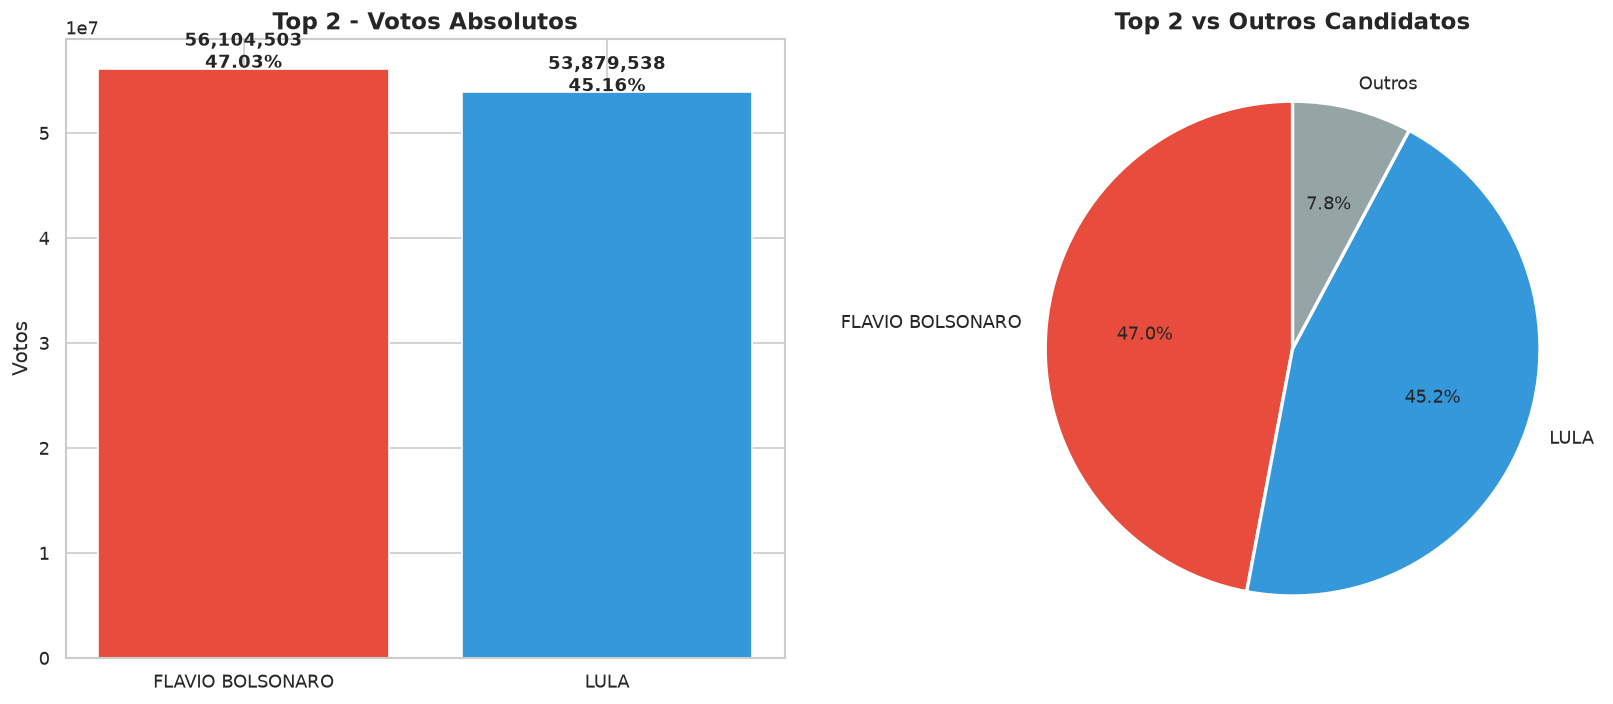

In [4]:

# Group: Top2 vs Others
df['grupo'] = df['nome_urna'].apply(lambda x: x if x in top2['nome_urna'].values else 'Outros')
df_grouped = df.groupby('grupo').agg({'votos':'sum','percentual':'sum'}).reset_index().sort_values('votos', ascending=False)

# For pie, keep top2 separate, others grouped
plt.figure(figsize=(14, 6))

# Subplot 1: Top2 comparison
plt.subplot(1, 2, 1)
bars = plt.bar(top2['nome_urna'], top2['votos'], color=['#e74c3c','#3498db'])
plt.title('Top 2 - Votos Absolutos', fontweight='bold')
plt.ylabel('Votos')
for bar, row in zip(bars, top2.itertuples()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100000, f"{row.votos:,}\n{row.percentual:.2f}%", ha='center', fontweight='bold')

# Subplot 2: Top2 vs Others pie
plt.subplot(1, 2, 2)
labels = list(top2['nome_urna']) + ['Outros']
sizes = list(top2['votos']) + [df[~df['nome_urna'].isin(top2['nome_urna'])]['votos'].sum()]
colors = ['#e74c3c','#3498db','#95a5a6']
plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=90, wedgeprops={'edgecolor':'white','linewidth':2})
plt.title('Top 2 vs Outros Candidatos', fontweight='bold')

plt.tight_layout()
plt.savefig('candidate_top2_vs_others.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Radar / Perfil dos Candidatos - Métricas Relativas

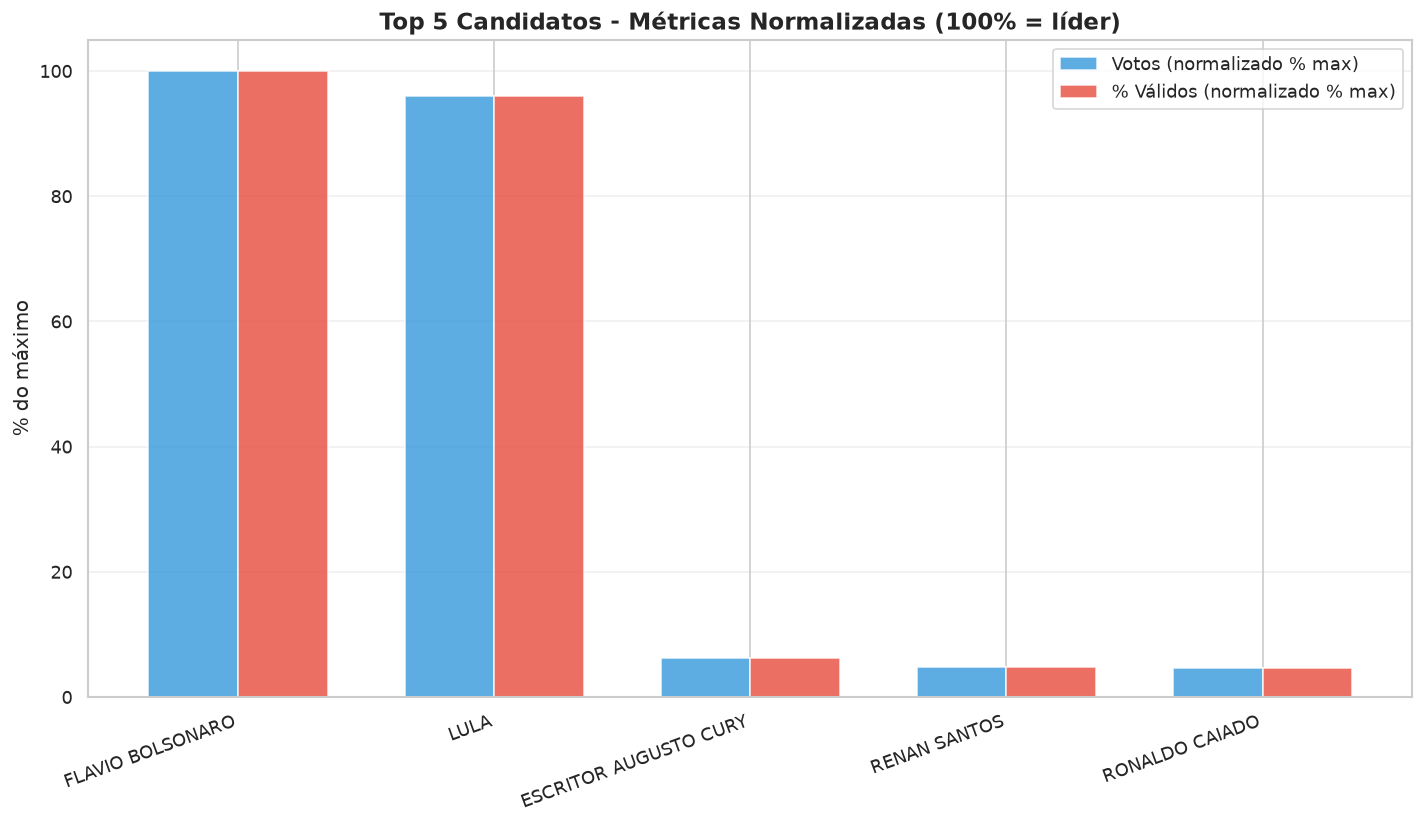

,nome_urna,votos,percentual,votos_norm,pct_norm
0,FLAVIO BOLSONARO,56104503,47.03,100.000000,100.000000
1,LULA,53879538,45.16,96.034249,96.023815
2,ESCRITOR AUGUSTO CURY,3448569,2.89,6.146688,6.145014
3,RENAN SANTOS,2675887,2.24,4.769469,4.762917
4,RONALDO CAIADO,2605148,2.18,4.643385,4.635339


In [5]:

# Normalize metrics for radar-like bar comparison
metrics = df.head(5).copy()
metrics['votos_norm'] = metrics['votos'] / metrics['votos'].max() * 100
metrics['pct_norm'] = metrics['percentual'] / metrics['percentual'].max() * 100

fig, ax = plt.subplots(figsize=(12, 7))
x = np.arange(len(metrics))
width = 0.35
bars1 = ax.bar(x - width/2, metrics['votos_norm'], width, label='Votos (normalizado % max)', color='#3498db', alpha=0.8)
bars2 = ax.bar(x + width/2, metrics['pct_norm'], width, label='% Válidos (normalizado % max)', color='#e74c3c', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(metrics['nome_urna'], rotation=20, ha='right')
ax.set_ylabel('% do máximo')
ax.set_title('Top 5 Candidatos - Métricas Normalizadas (100% = líder)', fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('candidate_normalized.png', dpi=150, bbox_inches='tight')
plt.show()

metrics[['nome_urna','votos','percentual','votos_norm','pct_norm']]


## 5. Análise de Coligações e Federações

                                      agregacao    votos                candidatos
                                PARTIDO LIBERAL 56104503          FLAVIO BOLSONARO
                         BRASIL PRONTO PRA MAIS 53879538                      LULA
                       BRASIL DOS NOSSOS SONHOS  3448569     ESCRITOR AUGUSTO CURY
                                 PARTIDO MISSÃO  2675887              RENAN SANTOS
                     PARTIDO SOCIAL DEMOCRÁTICO  2605148            RONALDO CAIADO
                                   PARTIDO NOVO   326488                      ZEMA
                                UNIDADE POPULAR   122911                    SAMARA
PARTIDO SOCIALISTA  DOS TRABALHADORES UNIFICADO    43103                HERTZ DIAS
                              DEMOCRACIA CRISTÃ    40043            CLARIANA BARAO
                   PARTIDO COMUNISTA BRASILEIRO    22693            EDMILSON COSTA
                                      DEMOCRATA    16881 VETERINÁRIO WILSON GRASSI
    

/tmp/ipykernel_2117/1868995492.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_agrup, x='agregacao', y='votos', palette='Set2')


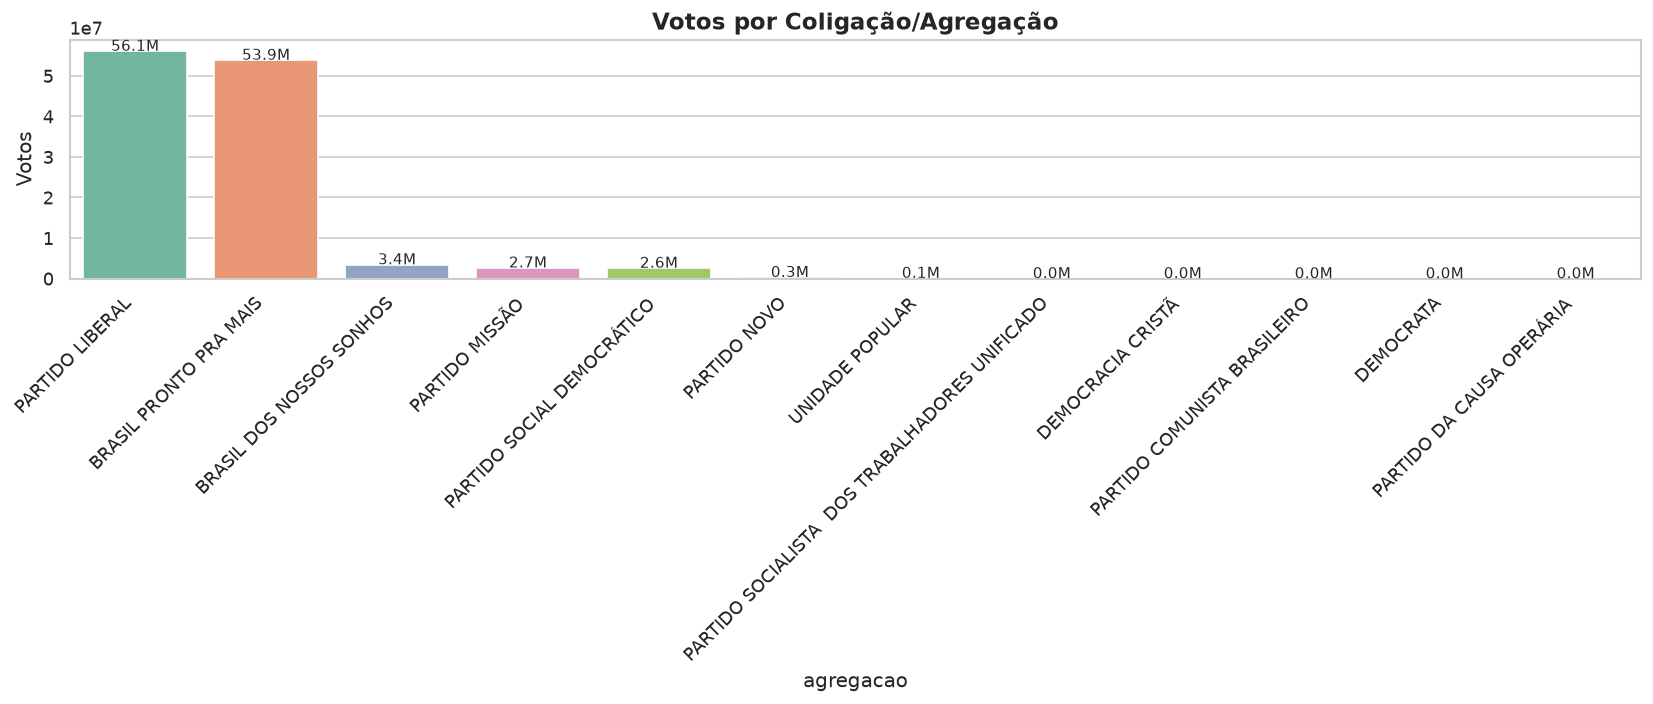

In [6]:

# Extract coalition info
df_coal = pd.DataFrame([{
    'nome_urna': c['nome_urna'],
    'partido': c['partido'],
    'agregacao': c['agregacao'],
    'votos': c['votos']
} for c in latest['candidatos']])

# Group by agregacao
df_agrup = df_coal.groupby('agregacao').agg({'votos':'sum','nome_urna': lambda x: ', '.join(x)}).reset_index().sort_values('votos', ascending=False)
df_agrup.rename(columns={'nome_urna':'candidatos'}, inplace=True)
print(df_agrup.to_string(index=False))

plt.figure(figsize=(14, 6))
sns.barplot(data=df_agrup, x='agregacao', y='votos', palette='Set2')
plt.title('Votos por Coligação/Agregação', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Votos')
for i, v in enumerate(df_agrup['votos']):
    plt.text(i, v + 50000, f"{v/1e6:.1f}M", ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('coalition_votes.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Simulação - O que falta para virar?

Líder atual: FLAVIO BOLSONARO com 56,104,503 votos

                candidato  votos_atuais  diferenca  votos_para_empatar_flip  pct_validos_necessario
                     LULA      53879538    2224965                  1112483                0.932503
    ESCRITOR AUGUSTO CURY       3448569   52655934                 26327968               22.068562
             RENAN SANTOS       2675887   53428616                 26714309               22.392399
           RONALDO CAIADO       2605148   53499355                 26749678               22.422046
                     ZEMA        326488   55778015                 27889008               23.377053
                   SAMARA        122911   55981592                 27990797               23.462374
               HERTZ DIAS         43103   56061400                 28030701               23.495822
           CLARIANA BARAO         40043   56064460                 28032231               23.497105
           EDMILSON COSTA         22693   560818

/tmp/ipykernel_2117/3295523473.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_sim, x='candidato', y='diferenca', palette='coolwarm')


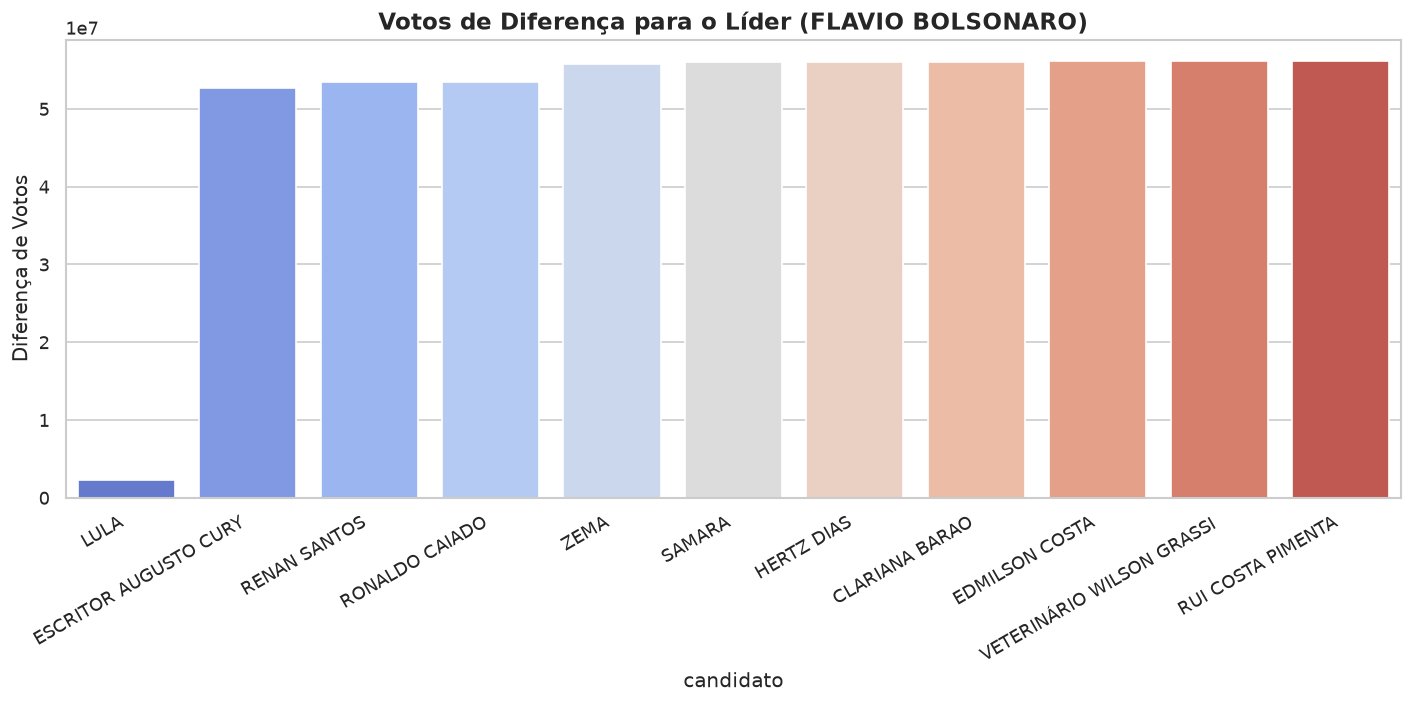

In [7]:

# For each candidate, how many votes would need to flip from leader to tie?
lider = df.iloc[0]
print(f"Líder atual: {lider['nome_urna']} com {lider['votos']:,} votos")
print()

sim_data = []
for _, row in df.iterrows():
    if row['nome_urna'] == lider['nome_urna']:
        continue
    diff = lider['votos'] - row['votos']
    # votes needed to tie: diff/2 + 1 (if flipping)
    need_flip = diff // 2 + 1
    pct_total = need_flip / latest['votos_validos'] * 100
    sim_data.append({
        'candidato': row['nome_urna'],
        'votos_atuais': row['votos'],
        'diferenca': diff,
        'votos_para_empatar_flip': need_flip,
        'pct_validos_necessario': pct_total
    })

df_sim = pd.DataFrame(sim_data).sort_values('diferenca')
print(df_sim.to_string(index=False))

plt.figure(figsize=(12, 6))
sns.barplot(data=df_sim, x='candidato', y='diferenca', palette='coolwarm')
plt.title(f"Votos de Diferença para o Líder ({lider['nome_urna']})", fontweight='bold')
plt.ylabel('Diferença de Votos')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('votes_needed_to_tie.png', dpi=150, bbox_inches='tight')
plt.show()
